In [1]:
import numpy as np

def calculate_snr(reference, estimate):
    """
    Calculate reference-based SNR in dB.
    """
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError(
            "Reference and estimate must have the same shape."
        )

    signal_power = np.sum(reference ** 2)
    error_power = np.sum((reference - estimate) ** 2)

    if error_power == 0:
        return float("inf")

    if signal_power == 0:
        return float("-inf")

    return float(10 * np.log10(signal_power / error_power))

In [2]:
reference = np.array([10, 20, 30, 40])
estimate = np.array([11, 19, 31, 39])

snr = calculate_snr(reference, estimate)

print(f"SNR: {snr:.2f} dB")

SNR: 28.75 dB



Inactive sensors: 4 (12.5%)
Incomplete SNR: 17.67 dB
Linear SNR:     50.14 dB
Spline SNR:     52.13 dB

Inactive sensors: 8 (25.0%)
Incomplete SNR: 11.76 dB
Linear SNR:     44.83 dB
Spline SNR:     52.17 dB

Inactive sensors: 12 (37.5%)
Incomplete SNR: 8.06 dB
Linear SNR:     38.93 dB
Spline SNR:     52.42 dB


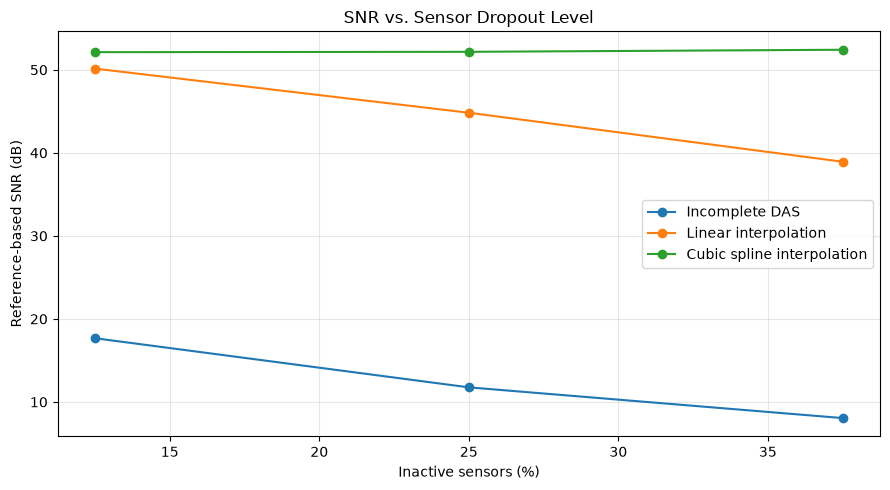


Results saved to outputs/day42_snr_robustness_results.json


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from scipy.interpolate import interp1d, CubicSpline

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Simulation parameters
c = 1500.0
fs = 10e6
n_sensors = 32
num_samples = 600
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, n_sensors)
sensor_y = np.zeros(n_sensors)

source_x = 5e-3
source_y = 20e-3

time = np.arange(num_samples) / fs

# Image grid
x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# Simulate signals
signals = np.zeros((n_sensors, num_samples))

for i in range(n_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2
        + (source_y - sensor_y[i])**2
    )
    arrival_time = distance / c

    signals[i, :] = np.exp(
        -((time - arrival_time) / pulse_width)**2
    )

# DAS reconstruction
def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(n_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2
            + (Y - sensor_y[i])**2
        )
        travel_time_map = distance_map / c

        sampled_signal = np.interp(
            travel_time_map.ravel(),
            time,
            signal_matrix[i, :],
            left=0,
            right=0
        )

        image += sampled_signal.reshape(X.shape)

    return image

# SNR calculation
def calculate_snr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Reference and estimate shapes must match.")

    signal_power = np.sum(reference**2)
    error_power = np.sum((reference - estimate)**2)

    if error_power == 0:
        return float("inf")
    if signal_power == 0:
        return float("-inf")

    return float(10 * np.log10(signal_power / error_power))

# Full-array reference image
reference_image = reconstruct_das(signals)

# Test different dropout levels
dropout_counts = [4, 8, 12]
results = {}

# Fixed, reproducible sensor order for nested dropout tests
rng = np.random.default_rng(42)
dropout_order = rng.permutation(n_sensors)

for n_missing in dropout_counts:
    inactive_indices = dropout_order[:n_missing]

    damaged_signals = signals.copy()
    damaged_signals[inactive_indices, :] = 0

    # Reconstruct without interpolation
    incomplete_image = reconstruct_das(damaged_signals)

    # Linear interpolation across sensors
    sensor_positions = np.arange(n_sensors)
    active_indices = np.setdiff1d(
        sensor_positions, inactive_indices
    )

    linear_interpolator = interp1d(
        active_indices,
        damaged_signals[active_indices, :],
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    linear_signals = damaged_signals.copy()
    linear_signals[inactive_indices, :] = (
        linear_interpolator(inactive_indices)
    )
    linear_image = reconstruct_das(linear_signals)

    # Cubic spline interpolation across sensors
    spline_interpolator = CubicSpline(
        active_indices,
        damaged_signals[active_indices, :],
        axis=0,
        bc_type="natural",
        extrapolate=True
    )

    spline_signals = damaged_signals.copy()
    spline_signals[inactive_indices, :] = (
        spline_interpolator(inactive_indices)
    )
    spline_image = reconstruct_das(spline_signals)

    results[str(n_missing)] = {
        "dropout_count": int(n_missing),
        "dropout_percentage": float(
            100 * n_missing / n_sensors
        ),
        "inactive_sensor_indices": [
            int(i) for i in inactive_indices
        ],
        "snr_incomplete_db": calculate_snr(
            reference_image, incomplete_image
        ),
        "snr_linear_db": calculate_snr(
            reference_image, linear_image
        ),
        "snr_spline_db": calculate_snr(
            reference_image, spline_image
        )
    }

# Print results
for count, result in results.items():
    print(f"\nInactive sensors: {count} "
          f"({result['dropout_percentage']:.1f}%)")
    print(f"Incomplete SNR: {result['snr_incomplete_db']:.2f} dB")
    print(f"Linear SNR:     {result['snr_linear_db']:.2f} dB")
    print(f"Spline SNR:     {result['snr_spline_db']:.2f} dB")

# Plot SNR comparison
percentages = [
    results[str(n)]["dropout_percentage"]
    for n in dropout_counts
]

plt.figure(figsize=(9, 5))

plt.plot(
    percentages,
    [results[str(n)]["snr_incomplete_db"]
     for n in dropout_counts],
    marker="o",
    label="Incomplete DAS"
)
plt.plot(
    percentages,
    [results[str(n)]["snr_linear_db"]
     for n in dropout_counts],
    marker="o",
    label="Linear interpolation"
)
plt.plot(
    percentages,
    [results[str(n)]["snr_spline_db"]
     for n in dropout_counts],
    marker="o",
    label="Cubic spline interpolation"
)

plt.xlabel("Inactive sensors (%)")
plt.ylabel("Reference-based SNR (dB)")
plt.title("SNR vs. Sensor Dropout Level")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/day42_snr_robustness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save numerical results
with open(
    output_dir / "day42_snr_robustness_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nResults saved to outputs/day42_snr_robustness_results.json")